In [1]:
%reload_ext autoreload
%autoreload 2

from turbos.sim.p3d.p3d import P3D
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np

run = P3D(
    "/archive/tulasi/MEGARUNS_DATA_SUBSET/149p6",
    filenum="000",
)
# #419
# ds = run.load_xarray(419, variables=['Pe', 'ue', 'Pi', 'ui', 'ne', 'ni', 'E'])
# print(ds)
ds = xr.open_dataset('../data/149p6_rs.nc')

In [2]:
from turbos.filter import kfilter
kf = 150

ds['Pe'] = kfilter(ds['Pe'], kf)
ds['ue'] = kfilter(ds['ue'], kf)
ds['Pi'] = kfilter(ds['Pi'], kf)
ds['ui'] = kfilter(ds['ui'], kf)

In [3]:
print(len(ds.x))

4096


In [4]:
from turbos.pressure_strain import pressure_strain
PSe = pressure_strain(ds['Pe'], ds['ue'])
ds['PiDe'], ds['pthe'] = PSe['PiD'], PSe['pth']

PSi = pressure_strain(ds['Pi'], ds['ui'])
ds['PiDi'], ds['pthi']  = PSi['PiD'], PSi['pth']
ds['JE'] = (ds["J"] * ds["E"]).sum("c")

In [5]:
from scipy.ndimage import uniform_filter, gaussian_filter

def boxcar_filter(field, ell, dx, dy):
    nx = max(1, round(ell / dx))
    ny = max(1, round(ell / dy))

    nx += (nx % 2 == 0)
    ny += (ny % 2 == 0)

    return uniform_filter(
        field,
        size=(len(ds.x.values), len(ds.y.values)),
        mode="wrap"
    )

In [6]:
def coarse_grain(field, ell, dx, dy, kind='boxcar'):
    """Centered 2D filter with periodic boundary conditions.

    For boxcar, ell is the approximate filter width in both x and y.
    For Gaussian, ell is sigma in each spatial direction (one convention).
    """
    if ell == 0:
        return field
    if kind == 'boxcar':
        def odd_width(width):
            n = max(1, int(round(width)))
            return n if n % 2 else n + 1
        widths = (odd_width(ell / dx), odd_width(ell / dy))
        return uniform_filter(field, size=widths, mode='wrap')
    elif kind == 'gaussian':
        return gaussian_filter(field, sigma=(ell / dx, ell / dy),
                               mode='wrap', truncate=4.0)
    else:
        raise ValueError("kind must be 'boxcar' or 'gaussian'")

In [7]:
ns = np.logspace(0, 1, num=10)

In [8]:
# dx = (ds.x[1] - ds.x[0]).values
# dy = (ds.y[1] - ds.y[0]).values


# n = 30
# for species in ['e', 'i']:
#     print(species)
#     # ns = np.logspace(np.log10(0.05), np.log10(70), num=n)
#     # ells = ns * dx
#     ells = np.logspace(np.log10(5e-2), np.log10(70), num=n)
#     # print(ells)
#     num = 0
#     l_filter = {'ptheta': [], 'PiD': [], 'total': []}
#     for ell in np.asarray(ells):
#         print(num, ell)
#         num += 1
#         Pe_bar = xr.apply_ufunc(
#             coarse_grain,
#             ds[f'P{species}'],
#             input_core_dims=[["x", "y"]],
#             output_core_dims=[["x", "y"]],
#             kwargs={"ell": ell, "dx": dx, "dy": dy, "kind": "boxcar"},
#             vectorize=True,
#         )

#         ne_bar = coarse_grain(ds[f'n{species}'], ell, dx, dy, kind="boxcar")

#         ue_tilde = ds[f'u{species}'].copy()

#         for i in range(3):
#             nue_bar = coarse_grain(
#                 ds[f'n{species}'] * ds[f'u{species}'].isel(c=i),
#                 ell,
#                 dx,
#                 dy,
#                 kind="boxcar"
#             )

#             ue_tilde.loc[{"c": ds[f'u{species}'].c.values[i]}] = nue_bar / ne_bar


#         PS = pressure_strain(Pe_bar, ue_tilde)
#         l_filter['ptheta'].append(np.mean(PS['pth'].values))
#         l_filter['PiD'].append(np.mean(PS['PiD'].values))
#         l_filter['total'].append(np.mean((PS['pth'] + PS['PiD']).values))

#     import json

#     json_output = json.dumps(l_filter, indent=4, )
#     print(json_output)

#     with open(f"../data/l_filter({species}).json", "w") as f:
#         f.write(json_output)


In [9]:
n = 30
ells = np.logspace(np.log10(5e-2), np.log10(70), num=n)

In [10]:
print(ells)

[5.00000000e-02 6.41884928e-02 8.24032521e-02 1.05786811e-01
 1.35805919e-01 1.74343545e-01 2.23816988e-01 2.87329502e-01
 3.68864953e-01 4.73537707e-01 6.07913434e-01 7.80420941e-01
 1.00188088e+00 1.28618447e+00 1.65116485e+00 2.11971566e+00
 2.72122707e+00 3.49342928e+00 4.48475920e+00 5.75739868e+00
 7.39117487e+00 9.48856749e+00 1.21811369e+01 1.56377764e+01
 2.00753059e+01 2.57720726e+01 3.30854099e+01 4.24740518e+01
 5.45269074e+01 7.00000000e+01]


In [11]:
import json

with open("../data/l_filter(i).json", "r", encoding="utf-8") as file:
    li_filter = json.load(file)

with open("../data/l_filter(e).json", "r", encoding="utf-8") as file:
    l_filter = json.load(file)


total = {'ptheta': [], 'PiD': [], 'total': []}

total['ptheta'] = np.array(li_filter['ptheta']) + np.array(l_filter['ptheta'])
total['PiD'] = np.array(li_filter['PiD']) + np.array(l_filter['PiD'])
total['total'] =  np.array(li_filter['PiD']) + np.array(li_filter['ptheta']) + np.array(l_filter['PiD']) + np.array(l_filter['ptheta'])

In [12]:
print(total['total'])

[1.62274471e-04 1.62281374e-04 1.62281374e-04 1.62281374e-04
 1.60393438e-04 1.60393438e-04 1.57617534e-04 1.54231111e-04
 1.50459350e-04 1.46479842e-04 1.38329420e-04 1.30270442e-04
 1.18690923e-04 1.04520409e-04 8.91606093e-05 7.18827878e-05
 5.70756021e-05 4.28889250e-05 3.23564801e-05 2.40823683e-05
 1.86231780e-05 1.46730478e-05 1.25031748e-05 1.13193839e-05
 1.02172248e-05 9.14626909e-06 8.03484010e-06 6.80571732e-06
 5.31682718e-06 3.62501253e-06]


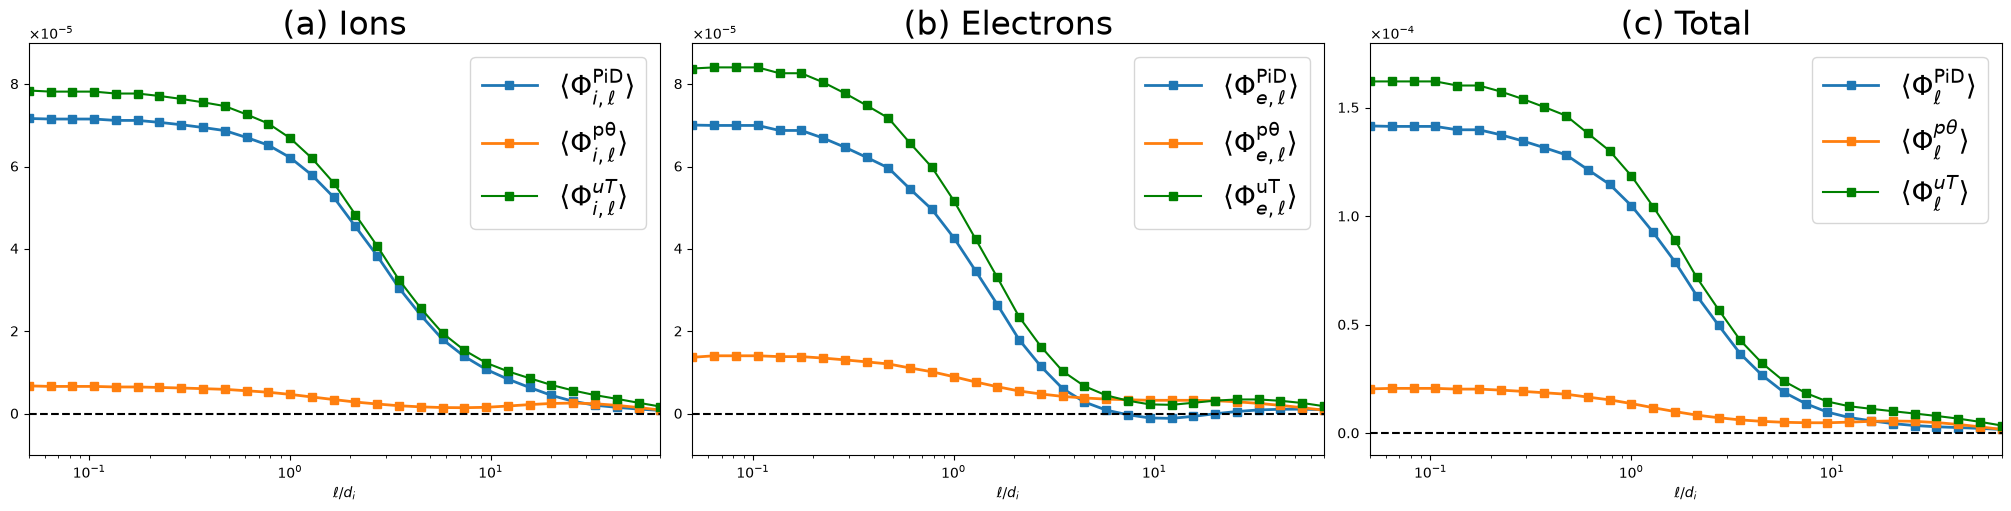

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5), layout = 'constrained')
plt.rcParams.update({'font.size': 20})
for a in ax.ravel():
    a.ticklabel_format(axis="both", style="sci", scilimits=(0, 0), useMathText=True)
n = 30
ells = np.logspace(np.log10(5e-2), np.log10(70), num=n)
ax[0].semilogx(ells, li_filter['PiD'],    marker = 's', c='tab:blue', lw=2, label=r'$\langle \Phi_{i,\ell}^{\mathrm{PiD}}\rangle$')
ax[0].semilogx(ells, li_filter['ptheta'], marker = 's', c='tab:orange', lw=2, label = r'$\langle \Phi_{i,\ell}^{\mathrm{p \theta}}\rangle$')
ax[0].semilogx(ells, li_filter['total'],  marker = 's', c = 'green', label = r'$\langle \Phi_{i,\ell}^{uT} \rangle$')
ax[0].axhline(0, ls = '--', c = 'black')
ax[0].set_ylim(-1e-5, 9e-5)
ax[0].set_xlim(5e-2, 70)
ax[0].set_title('(a) Ions')


ax[1].semilogx(ells, l_filter['PiD'],    marker = 's', c='tab:blue', lw=2, label=r'$\langle \Phi_{e,\ell}^{\mathrm{PiD}}\rangle$')
ax[1].semilogx(ells, l_filter['ptheta'], marker = 's', c='tab:orange', lw=2, label = r'$\langle \Phi_{e,\ell}^{\mathrm{p \theta}}\rangle$')
ax[1].semilogx(ells, l_filter['total'],  marker = 's', c = 'green', label = r'$\langle \Phi_{e,\ell}^{\mathrm{uT}}\rangle$')
ax[1].axhline(0, ls = '--', c = 'black')
ax[1].set_ylim(-1e-5, 9e-5)
ax[1].set_xlim(5e-2, 70)
ax[1].set_title('(b) Electrons')

ax[2].semilogx(ells, total['PiD'],    marker = 's', c='tab:blue', lw=2, label=r'$\langle \Phi_\ell^{\mathrm{PiD}}\rangle$')
ax[2].semilogx(ells, total['ptheta'], marker = 's', c='tab:orange', lw=2, label = r'$\langle \Phi_\ell^{p \theta}\rangle$')
ax[2].semilogx(ells, total['total'],  marker = 's', c = 'green', label = r'$\langle \Phi_{\ell}^{uT} \rangle$')
ax[2].axhline(0, ls = '--', c = 'black')
ax[2].set_ylim(-1e-5, 18e-5)
ax[2].set_xlim(5e-2, 70)
ax[2].set_title('(c) Total')

ax[0].legend()
ax[1].legend()
ax[2].legend()

ax[0].set_xlabel(r'$\ell/d_i$')
ax[1].set_xlabel(r'$\ell/d_i$')
ax[2].set_xlabel(r'$\ell/d_i$')



fig.savefig('../fig/SF_PS.png', dpi = 300)